In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

In [5]:
from rdkit import Chem

from src.features.conformers import (
    generate_conformers,
    optimize_conformers,
    remove_hydrogens,
)

from src.features.descriptors_3d import get_coordinates

from src.features.radial_features import (
    get_element_pair_distances,
    radial_centers,
    gaussian_rbf,
    element_pair_rbf,
)

In [12]:
smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

mol, conf_ids = generate_conformers(
    mol,
    n_conformers=1,
    random_seed=42,
)

optimization_results = optimize_conformers(
    mol,
    force_field="MMFF",
)

mol = remove_hydrogens(mol)

coords = get_coordinates(
    mol,
    conf_id=0,
)

In [13]:
print(mol.GetNumAtoms())

3


In [14]:
pair_distances = get_element_pair_distances(
    mol,
    coords,
)

for pair, distances in pair_distances.items():
    print(pair, distances)

('C', 'C') [1.51460394]
('C', 'O') [2.40433727 1.42017779]


In [15]:
centers = radial_centers(
    min_distance=0.5,
    max_distance=4.0,
    n_centers=100,
)

gamma = 8.0

In [16]:
cc_distances = pair_distances[("C", "C")]

print(cc_distances)

[1.51460394]


In [17]:
cc_rbf = gaussian_rbf(
    distances=cc_distances,
    centers=centers,
    gamma=gamma,
)

print(cc_rbf.shape)

(1, 100)


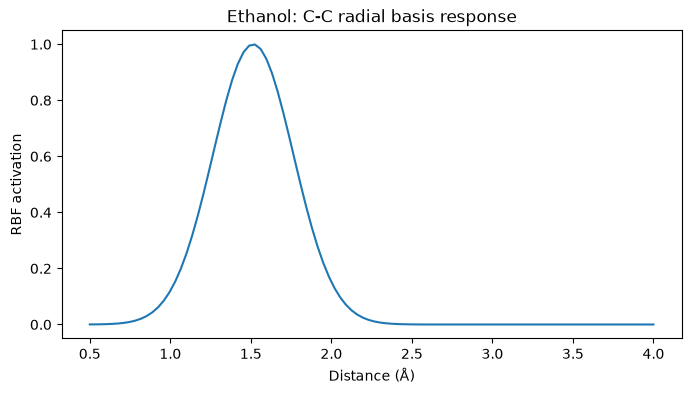

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    centers,
    cc_rbf[0],
)

plt.xlabel("Distance (Å)")
plt.ylabel("RBF activation")
plt.title("Ethanol: C-C radial basis response")

plt.show()

In [19]:
co_distances = pair_distances[("C", "O")]

print(co_distances)

[2.40433727 1.42017779]


In [20]:
co_rbf = gaussian_rbf(
    distances=co_distances,
    centers=centers,
    gamma=gamma,
)

print(co_rbf.shape)

(2, 100)


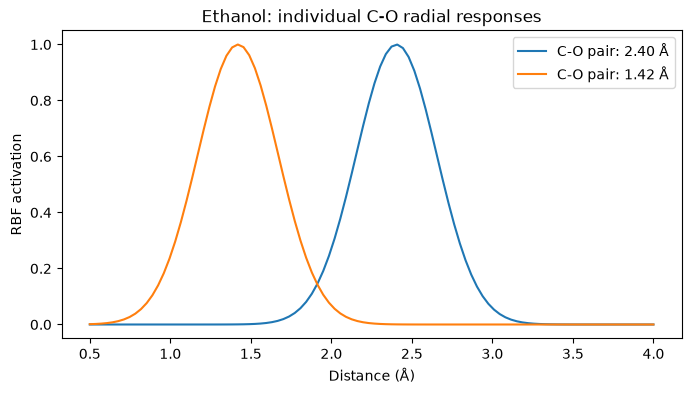

In [21]:
plt.figure(figsize=(8, 4))

for i, distance in enumerate(co_distances):

    plt.plot(
        centers,
        co_rbf[i],
        label=f"C-O pair: {distance:.2f} Å",
    )

plt.xlabel("Distance (Å)")
plt.ylabel("RBF activation")
plt.title("Ethanol: individual C-O radial responses")

plt.legend()

plt.show()

In [22]:
co_aggregated = np.mean(
    co_rbf,
    axis=0,
)

In [23]:
from src.features.radial_features import aggregate_rbf

co_aggregated = aggregate_rbf(
    co_rbf,
    normalize=True,
)

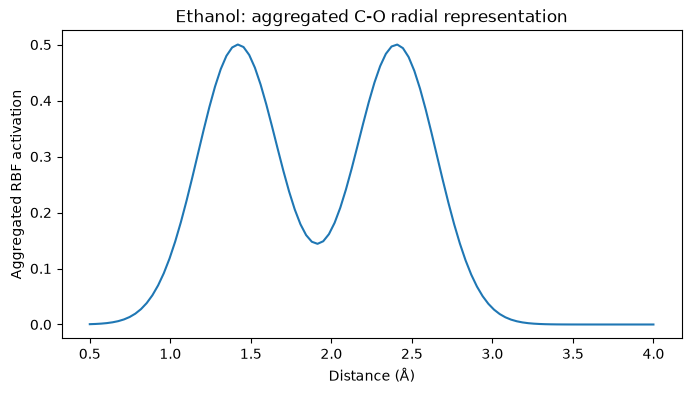

In [24]:
plt.figure(figsize=(8, 4))

plt.plot(
    centers,
    co_aggregated,
)

plt.xlabel("Distance (Å)")
plt.ylabel("Aggregated RBF activation")
plt.title("Ethanol: aggregated C-O radial representation")

plt.show()

In [25]:
elements = [
    "C",
    "O",
]

In [26]:
from src.features.radial_features import generate_element_pairs

element_pairs = generate_element_pairs(
    elements
)

print(element_pairs)

[('C', 'C'), ('C', 'O'), ('O', 'O')]


In [27]:
features = element_pair_rbf(
    mol=mol,
    coords=coords,
    centers=centers,
    gamma=gamma,
    element_pairs=element_pairs,
    normalize=True,
)

In [28]:
len(features)

300

In [29]:
oo_features = {
    key: value
    for key, value in features.items()
    if key.startswith("rbf_O_O")
}

print(max(oo_features.values()))

0.0


In [30]:
cc_curve = np.array([
    features[f"rbf_C_C_{k:02d}"]
    for k in range(len(centers))
])

co_curve = np.array([
    features[f"rbf_C_O_{k:02d}"]
    for k in range(len(centers))
])

oo_curve = np.array([
    features[f"rbf_O_O_{k:02d}"]
    for k in range(len(centers))
])

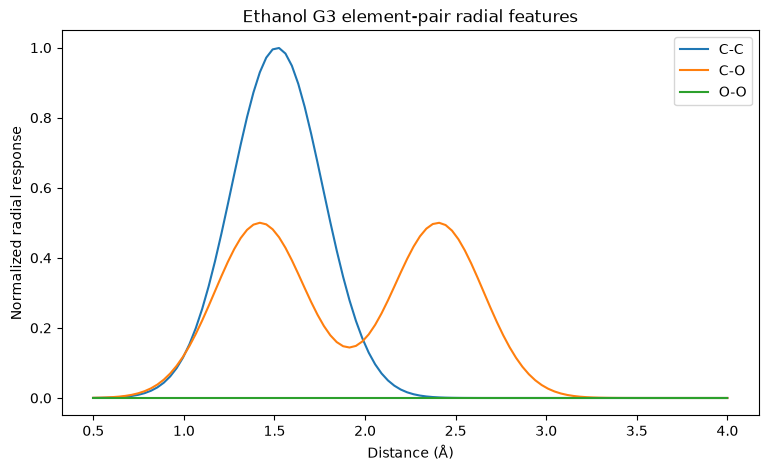

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    centers,
    cc_curve,
    label="C-C",
)

plt.plot(
    centers,
    co_curve,
    label="C-O",
)

plt.plot(
    centers,
    oo_curve,
    label="O-O",
)

plt.xlabel("Distance (Å)")
plt.ylabel("Normalized radial response")
plt.title("Ethanol G3 element-pair radial features")

plt.legend()

plt.show()

In [32]:
from src.features.radial_features import calculate_radial_features

features = calculate_radial_features(
    mol=mol,
    conf_id=0,
    elements=[
        "C",
        "O",
    ],
    min_distance=0.5,
    max_distance=4.0,
    n_centers=100,
    gamma=8.0,
    normalize=True,
)

In [33]:
list(features.items())[:10]

[('rbf_C_C_00', 0.0002651090517958256),
 ('rbf_C_C_01', 0.000465941299820526),
 ('rbf_C_C_02', 0.0008026992440215294),
 ('rbf_C_C_03', 0.0013554687129996308),
 ('rbf_C_C_04', 0.0022435778197365036),
 ('rbf_C_C_05', 0.0036400535665081857),
 ('rbf_C_C_06', 0.005788811502526556),
 ('rbf_C_C_07', 0.009023728875598047),
 ('rbf_C_C_08', 0.013787885390290432),
 ('rbf_C_C_09', 0.020650201222673616)]